# Comparative Explainable and Fair AI Analysis of XGBoost and LightGBM for Loan Approval Prediction Using SHAP
### Analysis notebook — M.Phil. in ICT, Nepal Open University
**Sagar Poudel** · NOU Reg. No. 2024210364 · Supervisor: Asst. Prof. Dr. Bhoj Raj Ghimire

This notebook runs the complete analysis for my research report. It works on two real, public loan datasets that
both record the protected attributes I need (**sex** and **age**): **Home Credit Default Risk** (307,511 loan
applications) and **German Credit** (1,000 applications).

**The question my study answers:** *which of the two models is fairer, why, and can it be fixed without losing accuracy?*

| Objective | What it does | Where |
|---|---|---|
| **O1** | Train and fairly compare XGBoost and LightGBM (identical preprocessing, split, seed) | Section 1 |
| **O2** | Audit and compare fairness across sex and age (demographic parity, equal opportunity) | Section 2 |
| **O3** | Explain both models with SHAP and diagnose *why* the unfairness happens | Section 3 |
| **O4** | Check the explanations are faithful, stable and consistent | Section 4 |
| **O5** | Apply mitigation and report the fairness-accuracy trade-off | Section 5 |

**Two design decisions worth stating up front.**
1. The models are trained **without** sex and age as inputs. Any unfairness that appears therefore comes from
   *proxy* features, which is exactly what Section 3 sets out to uncover.
2. I frame the machine-learning target as **risk** (`1 = high risk / reject`) and the *favourable* outcome for
   fairness as **approval** (`approved = 1`). Fairness is always measured on the approve/reject decision.

## 0. Setup

In [1]:
import warnings, json, os, numpy as np, pandas as pd
warnings.filterwarnings('ignore')
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
from sklearn.utils.class_weight import compute_sample_weight
from scipy.stats import spearmanr
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import shap
from fairlearn.metrics import (MetricFrame, selection_rate, true_positive_rate, false_positive_rate,
                               demographic_parity_difference, equalized_odds_difference)
from fairlearn.postprocessing import ThresholdOptimizer

SEED = 42
np.random.seed(SEED)

# ---- configuration -------------------------------------------------------
HC_MAX_ROWS  = None    # None = full 307,511 Home Credit rows. Set e.g. 50000 for a fast trial run.
SHAP_N       = 3000    # rows used to compute SHAP values
ROBUST_N     = 60000   # subsample for the explanation-robustness experiments (Section 4)
BOOT         = 4       # bootstrap repetitions for the stability check
CI_BOOT      = 300     # bootstrap repetitions for confidence intervals
ASSETS       = 'report_assets_v2'
os.makedirs(ASSETS, exist_ok=True)

plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 160, 'axes.grid': True,
                     'grid.alpha': .3, 'font.size': 9, 'figure.autolayout': True})
NAVY, RED, GREEN, ORANGE = '#1F497D', '#C0504D', '#4F81BD', '#E39B29'

def savefig(fig, name):
    path = os.path.join(ASSETS, name)
    fig.savefig(path, bbox_inches='tight')
    print('saved', path)

print('Setup complete. Home Credit rows:', HC_MAX_ROWS or 'ALL (307,511)')

Setup complete. Home Credit rows: ALL (307,511)


### Loading and preprocessing

Both datasets go through **one identical path**: the protected attributes are pulled out and held aside, every
categorical column is encoded the same way, and nothing else is treated differently between the two models.

In [2]:
def load_dataset(name):
    """Return X (features, no protected attributes), risk target, approved label, sensitive frame."""
    if name == 'German Credit':
        df = pd.read_csv('data/german_credit.csv')
        drop = ['target', 'approved', 'sex', 'age', 'age_group', 'personal_status_sex']
    else:
        df = pd.read_csv('data/home_credit.csv')
        df = df[df['sex'].isin(['male', 'female'])]          # drop the 4 'unknown' rows
        if HC_MAX_ROWS and len(df) > HC_MAX_ROWS:
            df = df.groupby('approved', group_keys=False).apply(
                lambda g: g.sample(int(round(HC_MAX_ROWS * len(g) / len(df))), random_state=SEED))
        drop = ['SK_ID_CURR', 'TARGET', 'approved', 'sex', 'age', 'age_group', 'CODE_GENDER', 'DAYS_BIRTH']
    approved = df['approved'].astype(int).reset_index(drop=True)
    sens = df[['sex', 'age_group']].reset_index(drop=True)
    X = df.drop(columns=[c for c in drop if c in df.columns]).reset_index(drop=True)
    for c in X.columns:
        if X[c].dtype == object:
            X[c] = X[c].astype('category').cat.codes
    risk = (1 - approved)                                     # ML target: 1 = high risk / reject
    return X, risk, approved, sens

def make_models():
    common = dict(n_estimators=250, max_depth=6, learning_rate=0.1,
                  subsample=0.9, colsample_bytree=0.9, random_state=SEED, n_jobs=-1)
    return {'XGBoost':  XGBClassifier(eval_metric='logloss', **common),
            'LightGBM': LGBMClassifier(verbose=-1, **common)}

def perf(y, yp, ys):
    return dict(accuracy=accuracy_score(y, yp), precision=precision_score(y, yp, zero_division=0),
                recall=recall_score(y, yp, zero_division=0), f1=f1_score(y, yp, zero_division=0),
                auc=roc_auc_score(y, ys))

def shap_matrix(model, Xs):
    """Signed SHAP values (n, n_features) for the positive (risk) class."""
    sv = shap.TreeExplainer(model).shap_values(Xs)
    if isinstance(sv, list):
        sv = sv[-1]
    sv = np.asarray(sv)
    if sv.ndim == 3:
        sv = sv[..., -1]
    return sv

def fair_gaps(appr_true, appr_pred, s):
    return (float(demographic_parity_difference(appr_true, appr_pred, sensitive_features=s)),
            float(equalized_odds_difference(appr_true, appr_pred, sensitive_features=s)))

print('helpers ready')

helpers ready


---
## 1. Objective 1 — Train and fairly compare XGBoost and LightGBM

Both models see the same features, the same stratified 80/20 split, the same random seed and the same
class-balancing weights. The only thing that differs is the algorithm, so any difference is attributable to it.

In [3]:
D = {}
for ds in ['German Credit', 'Home Credit']:
    X, risk, approved, sens = load_dataset(ds)
    idx = np.arange(len(X))
    Xtr, Xte, rtr, rte, itr, ite = train_test_split(
        X, risk, idx, test_size=0.2, stratify=risk, random_state=SEED)
    sw = compute_sample_weight('balanced', rtr)
    s_te = sens.iloc[ite].reset_index(drop=True)
    appr_te = approved.iloc[ite].reset_index(drop=True).values

    models, preds, scores, shp = {}, {}, {}, {}
    for mn, m in make_models().items():
        m.fit(Xtr, rtr, sample_weight=sw)
        preds[mn]  = m.predict(Xte)
        scores[mn] = m.predict_proba(Xte)[:, 1]
        models[mn] = m
    D[ds] = dict(X=X, Xtr=Xtr, Xte=Xte, rtr=rtr, rte=rte, itr=itr, ite=ite, sens=sens,
                 s_te=s_te, appr_te=appr_te, sw=sw, models=models, preds=preds, scores=scores)
    print(f'{ds:15s} train={Xtr.shape}  test={Xte.shape}  approval rate={approved.mean():.3f}')

rows = []
for ds in D:
    for mn in ['XGBoost', 'LightGBM']:
        p = perf(D[ds]['rte'].values, D[ds]['preds'][mn], D[ds]['scores'][mn])
        rows.append(dict(dataset=ds, model=mn, **{k: round(v, 4) for k, v in p.items()}))
perf_df = pd.DataFrame(rows)
display(perf_df)

German Credit   train=(800, 18)  test=(200, 18)  approval rate=0.700

Home Credit     train=(246005, 118)  test=(61502, 118)  approval rate=0.919


,dataset,model,accuracy,precision,recall,f1,auc
0,German Credit,XGBoost,0.7700,0.6250,0.5833,0.6034,0.7915
1,German Credit,LightGBM,0.7600,0.6111,0.5500,0.5789,0.8014
2,Home Credit,XGBoost,0.7342,0.1762,0.6238,0.2748,0.7538
3,Home Credit,LightGBM,0.7208,0.1723,0.6463,0.2721,0.7560


**Is the difference between the two models real, or just noise?** A single accuracy number can mislead, so I
bootstrap the test set and report a 95% confidence interval for the *difference* in ROC-AUC. If the interval
contains zero, the two models are statistically indistinguishable.

In [4]:
auc_ci = {}
for ds in D:
    d = D[ds]; y = d['rte'].values
    a, b = d['scores']['XGBoost'], d['scores']['LightGBM']
    rng = np.random.RandomState(SEED); diffs = []
    for _ in range(CI_BOOT):
        bi = rng.randint(0, len(y), len(y))
        if len(np.unique(y[bi])) < 2:
            continue
        diffs.append(roc_auc_score(y[bi], a[bi]) - roc_auc_score(y[bi], b[bi]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    auc_ci[ds] = dict(auc_xgb=round(roc_auc_score(y, a), 4), auc_lgbm=round(roc_auc_score(y, b), 4),
                      diff=round(float(np.mean(diffs)), 4), ci_low=round(float(lo), 4),
                      ci_high=round(float(hi), 4), significant=bool(lo > 0 or hi < 0))
auc_ci_df = pd.DataFrame(auc_ci).T
display(auc_ci_df)
print('\n"significant" = the 95% CI for (XGBoost - LightGBM) AUC excludes zero.')

,auc_xgb,auc_lgbm,diff,ci_low,ci_high,significant
German Credit,0.7915,0.8014,-0.0099,-0.0344,0.0166,False
Home Credit,0.7538,0.756,-0.0021,-0.0043,-0.0,True



"significant" = the 95% CI for (XGBoost - LightGBM) AUC excludes zero.


saved report_assets_v2\fig01_performance.png


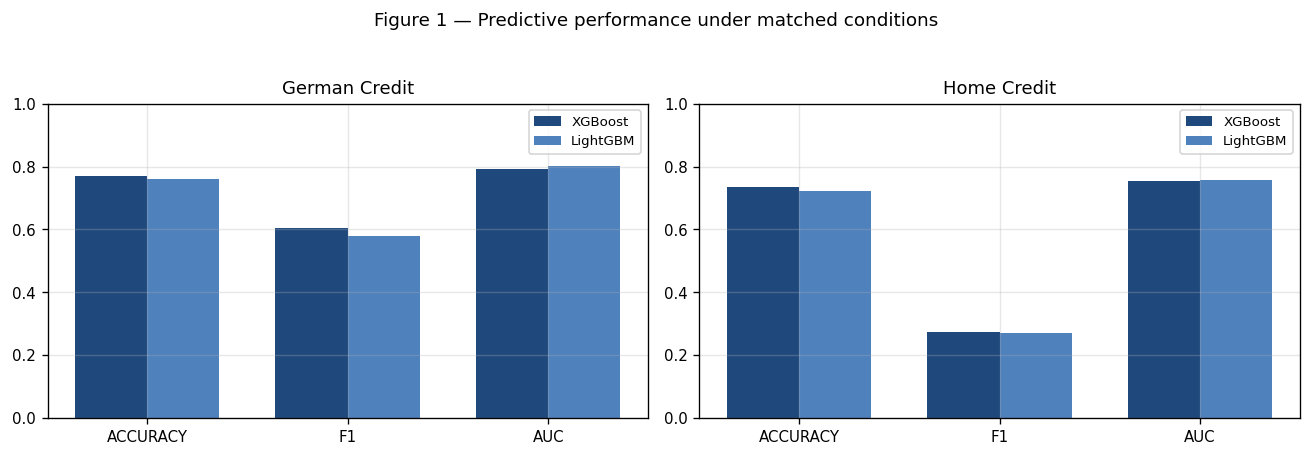

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
metrics = ['accuracy', 'f1', 'auc']
for ax, ds in zip(axes, D):
    sub = perf_df[perf_df.dataset == ds].set_index('model')
    x = np.arange(len(metrics)); w = 0.36
    for i, mn in enumerate(['XGBoost', 'LightGBM']):
        ax.bar(x + i * w, [sub.loc[mn, m] for m in metrics], w,
               label=mn, color=[NAVY, GREEN][i])
    ax.set_xticks(x + w / 2); ax.set_xticklabels([m.upper() for m in metrics])
    ax.set_ylim(0, 1); ax.set_title(f'{ds}'); ax.legend(fontsize=8)
fig.suptitle('Figure 1 — Predictive performance under matched conditions', y=1.04, fontsize=11)
savefig(fig, 'fig01_performance.png'); plt.show()

---
## 2. Objective 2 (core) — Fairness audit across sex and age

This is the heart of the study. For each model I measure, per group:

* **selection rate** — the share of applicants approved,
* **true-positive rate** — of the people who *should* be approved, how many are,
* **false-positive rate** and **accuracy**.

Then two summary gaps: the **demographic-parity difference** (gap in approval rates) and the
**equalized-odds difference** (gap in error rates). Both are "lower is fairer"; 0 means perfectly equal.

In [6]:
group_tables = {}
for ds in D:
    d = D[ds]
    for mn in ['XGBoost', 'LightGBM']:
        appr_pred = 1 - d['preds'][mn]
        for attr in ['sex', 'age_group']:
            mf = MetricFrame(
                metrics={'selection_rate': selection_rate, 'TPR': true_positive_rate,
                         'FPR': false_positive_rate, 'accuracy': accuracy_score},
                y_true=d['appr_te'], y_pred=appr_pred, sensitive_features=d['s_te'][attr].values)
            t = mf.by_group.copy(); t['n'] = d['s_te'][attr].value_counts().reindex(t.index).values
            group_tables[(ds, mn, attr)] = t.round(4)

for k, t in group_tables.items():
    print(f'--- {k[0]} | {k[1]} | by {k[2]} ---'); display(t)

--- German Credit | XGBoost | by sex ---


,selection_rate,TPR,FPR,accuracy,n
sensitive_feature_0,,,,,
female,0.6557,0.8049,0.35,0.7541,61
male,0.7482,0.8687,0.45,0.7770,139


--- German Credit | XGBoost | by age_group ---


,selection_rate,TPR,FPR,accuracy,n
sensitive_feature_0,,,,,
age_ge_25,0.7329,0.85,0.3902,0.7888,161
age_lt_25,0.6667,0.85,0.4737,0.6923,39


--- German Credit | LightGBM | by sex ---


,selection_rate,TPR,FPR,accuracy,n
sensitive_feature_0,,,,,
female,0.6721,0.7805,0.45,0.7049,61
male,0.7554,0.8788,0.45,0.7842,139


... (6 outputs left out)

--- Home Credit | LightGBM | by sex ---


,selection_rate,TPR,FPR,accuracy,n
sensitive_feature_0,,,,,
female,0.7339,0.7592,0.3974,0.7483,40544
male,0.6261,0.6634,0.2954,0.6676,20958


--- Home Credit | LightGBM | by age_group ---


,selection_rate,TPR,FPR,accuracy,n
sensitive_feature_0,,,,,
age_ge_25,0.7118,0.7413,0.3686,0.7326,59096
age_lt_25,0.3383,0.3692,0.1036,0.4306,2406


In [7]:
fair_rows = []
for ds in D:
    d = D[ds]
    for mn in ['XGBoost', 'LightGBM']:
        appr_pred = 1 - d['preds'][mn]
        for attr in ['sex', 'age_group']:
            s = d['s_te'][attr].values
            dp, eo = fair_gaps(d['appr_te'], appr_pred, s)
            # bootstrap CI on the DP gap
            rng = np.random.RandomState(SEED); vals = []
            for _ in range(CI_BOOT):
                bi = rng.randint(0, len(s), len(s))
                try:
                    vals.append(float(demographic_parity_difference(
                        d['appr_te'][bi], appr_pred[bi], sensitive_features=s[bi])))
                except Exception:
                    pass
            lo, hi = np.percentile(vals, [2.5, 97.5]) if vals else (np.nan, np.nan)
            fair_rows.append(dict(dataset=ds, model=mn, attribute=attr, dp_diff=round(dp, 4),
                                  dp_ci_low=round(float(lo), 4), dp_ci_high=round(float(hi), 4),
                                  eo_diff=round(eo, 4)))
fair_df = pd.DataFrame(fair_rows)
display(fair_df)

,dataset,model,attribute,dp_diff,dp_ci_low,dp_ci_high,eo_diff
0,German Credit,XGBoost,sex,0.0925,0.0056,0.2380,0.1000
1,German Credit,XGBoost,age_group,0.0663,0.0033,0.2466,0.0834
2,German Credit,LightGBM,sex,0.0833,0.0027,0.2411,0.0983
3,German Credit,LightGBM,age_group,0.0787,0.0028,0.2376,0.1117
4,Home Credit,XGBoost,sex,0.1052,0.0975,0.1126,0.1061
5,Home Credit,XGBoost,age_group,0.3644,0.3464,0.3819,0.3619
6,Home Credit,LightGBM,sex,0.1079,0.0995,0.1146,0.1019
7,Home Credit,LightGBM,age_group,0.3735,0.3566,0.3884,0.3721


saved report_assets_v2\fig02_fairness_gaps.png


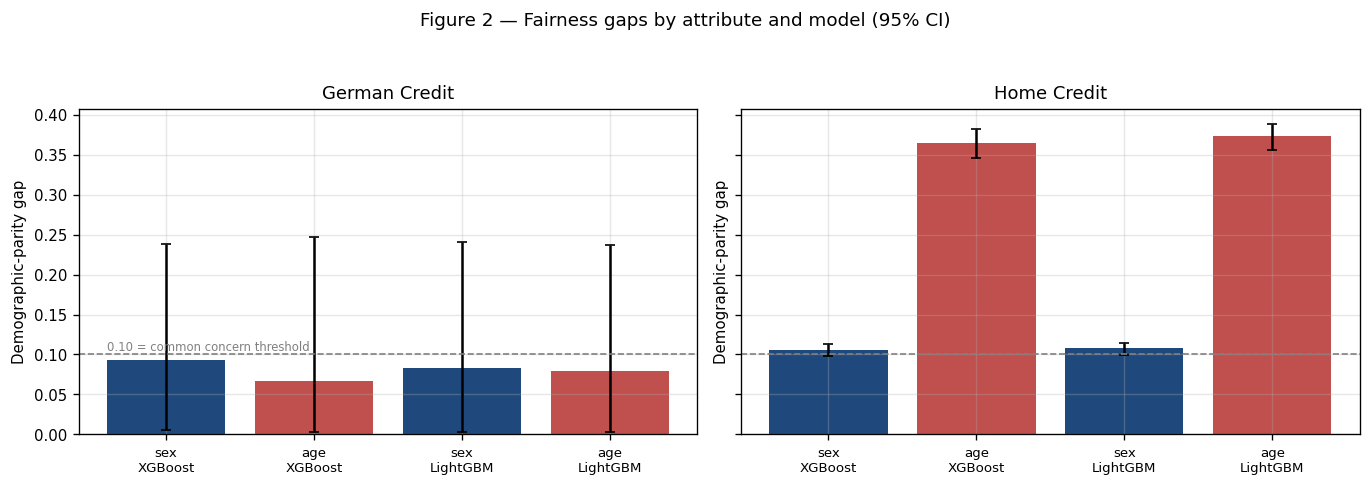

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
for ax, ds in zip(axes, D):
    sub = fair_df[fair_df.dataset == ds]
    labels = [f"{r.attribute.replace('_group','')}\n{r.model}" for r in sub.itertuples()]
    err = [[r.dp_diff - r.dp_ci_low for r in sub.itertuples()],
           [r.dp_ci_high - r.dp_diff for r in sub.itertuples()]]
    colors = [NAVY if r.attribute == 'sex' else RED for r in sub.itertuples()]
    ax.bar(labels, sub['dp_diff'], yerr=err, capsize=3, color=colors)
    ax.axhline(0.10, ls='--', c='gray', lw=1)
    ax.set_title(ds); ax.set_ylabel('Demographic-parity gap')
    ax.tick_params(axis='x', labelsize=8)
axes[0].text(-0.4, 0.105, '0.10 = common concern threshold', fontsize=7, color='gray')
fig.suptitle('Figure 2 — Fairness gaps by attribute and model (95% CI)', y=1.05, fontsize=11)
savefig(fig, 'fig02_fairness_gaps.png'); plt.show()

### 2.1 Intersectional fairness

Looking at sex and age one at a time can hide a problem that only shows up at the intersection — for example
young women. Here I combine the two attributes and compare approval rates across all four groups.

In [9]:
inter_rows = []
for ds in D:
    d = D[ds]
    combo = (d['s_te']['sex'] + ' & ' + d['s_te']['age_group'].str.replace('age_', '')).values
    for mn in ['XGBoost', 'LightGBM']:
        appr_pred = 1 - d['preds'][mn]
        mf = MetricFrame(metrics={'selection_rate': selection_rate, 'TPR': true_positive_rate},
                         y_true=d['appr_te'], y_pred=appr_pred, sensitive_features=combo)
        g = mf.by_group
        for grp, r in g.iterrows():
            inter_rows.append(dict(dataset=ds, model=mn, group=grp,
                                   selection_rate=round(float(r['selection_rate']), 4),
                                   TPR=round(float(r['TPR']), 4),
                                   n=int((combo == grp).sum())))
        print(f'{ds} | {mn}: intersectional selection-rate spread = '
              f'{float(g["selection_rate"].max() - g["selection_rate"].min()):.4f}')
inter_df = pd.DataFrame(inter_rows)
display(inter_df)

German Credit | XGBoost: intersectional selection-rate spread = 0.1250
German Credit | LightGBM: intersectional selection-rate spread = 0.1331


Home Credit | XGBoost: intersectional selection-rate spread = 0.4603


Home Credit | LightGBM: intersectional selection-rate spread = 0.4647


,dataset,model,group,selection_rate,TPR,n
0,German Credit,XGBoost,female & ge_25,0.6757,0.7857,37
1,German Credit,XGBoost,female & lt_25,0.6250,0.8462,24
2,German Credit,XGBoost,male & ge_25,0.7500,0.8696,124
3,German Credit,XGBoost,male & lt_25,0.7333,0.8571,15
4,German Credit,LightGBM,female & ge_25,0.7027,0.7857,37
5,German Credit,LightGBM,female & lt_25,0.6250,0.7692,24
6,German Credit,LightGBM,male & ge_25,0.7581,0.8804,124
7,German Credit,LightGBM,male & lt_25,0.7333,0.8571,15
8,Home Credit,XGBoost,female & ge_25,0.7612,0.7853,39235
9,Home Credit,XGBoost,female & lt_25,0.4171,0.4488,1309


saved report_assets_v2\fig03_intersectional.png


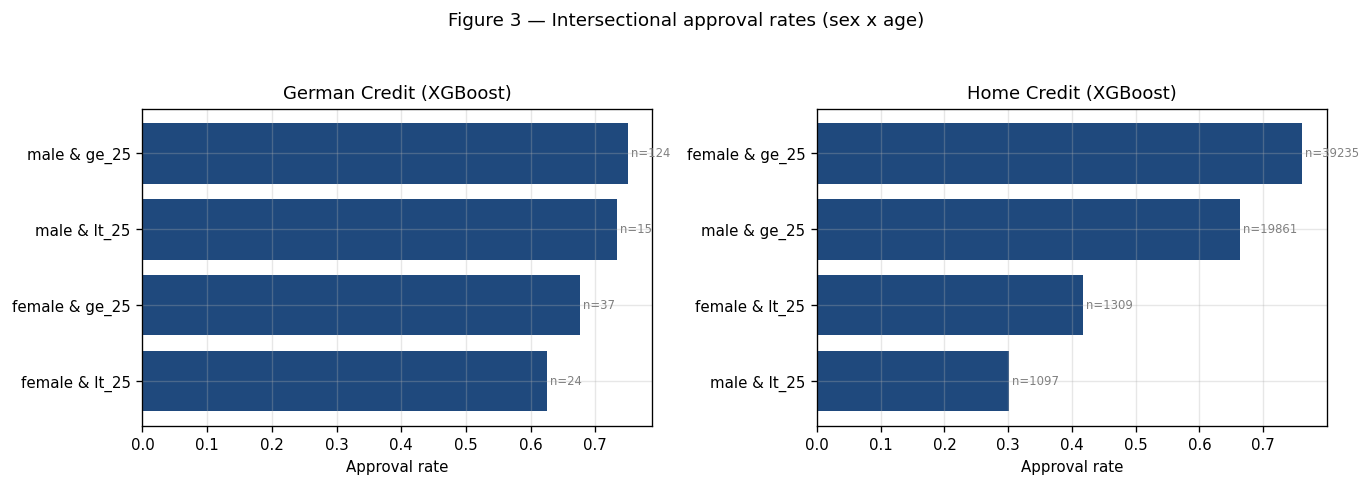

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for ax, ds in zip(axes, D):
    sub = inter_df[(inter_df.dataset == ds) & (inter_df.model == 'XGBoost')].sort_values('selection_rate')
    ax.barh(sub['group'], sub['selection_rate'], color=NAVY)
    for i, (v, n) in enumerate(zip(sub['selection_rate'], sub['n'])):
        ax.text(v + .005, i, f'n={n}', va='center', fontsize=7, color='gray')
    ax.set_xlabel('Approval rate'); ax.set_title(f'{ds} (XGBoost)')
fig.suptitle('Figure 3 — Intersectional approval rates (sex x age)', y=1.05, fontsize=11)
savefig(fig, 'fig03_intersectional.png'); plt.show()

### 2.2 Does the decision threshold change the picture?

A classifier's fairness is not a fixed property — it depends on where the approve/reject cut-off is placed.
This sweep shows how the sex gap and overall accuracy move together as the threshold changes, which is useful
context for the mitigation results in Section 5.

saved report_assets_v2\fig04_threshold_sweep.png


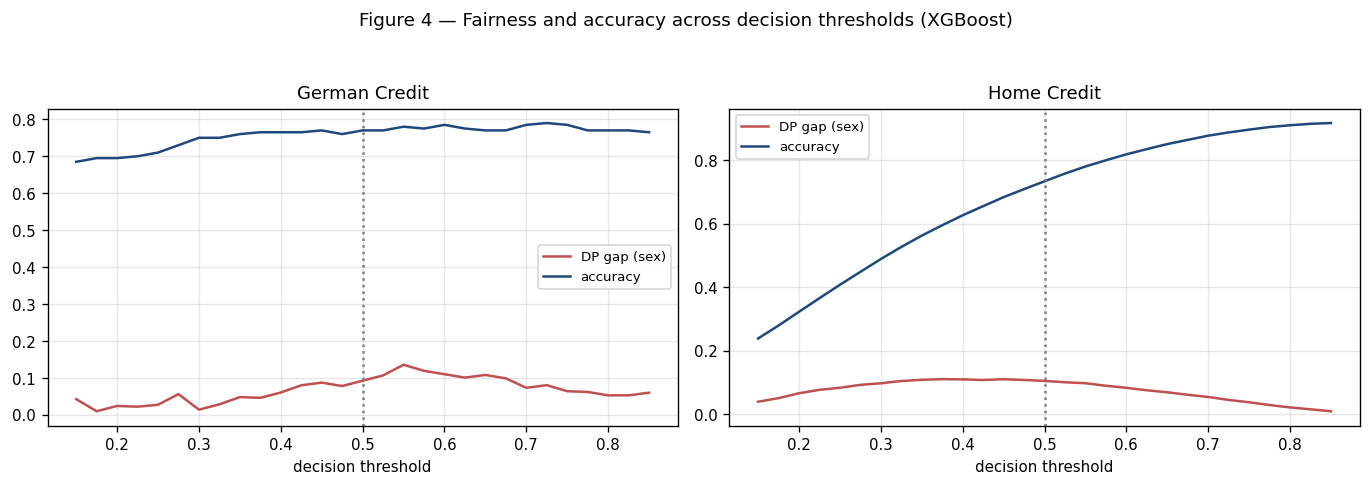

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
sweep_store = {}
for ax, ds in zip(axes, D):
    d = D[ds]; s = d['s_te']['sex'].values; ths = np.linspace(0.15, 0.85, 29)
    dps, accs = [], []
    for t in ths:
        pr = (d['scores']['XGBoost'] >= t).astype(int)
        dps.append(fair_gaps(d['appr_te'], 1 - pr, s)[0])
        accs.append(accuracy_score(d['rte'].values, pr))
    sweep_store[ds] = dict(thresholds=ths.tolist(), dp=dps, acc=accs)
    ax.plot(ths, dps, color=RED, label='DP gap (sex)')
    ax.plot(ths, accs, color=NAVY, label='accuracy')
    ax.axvline(0.5, ls=':', c='gray'); ax.set_xlabel('decision threshold'); ax.set_title(ds)
    ax.legend(fontsize=8)
fig.suptitle('Figure 4 — Fairness and accuracy across decision thresholds (XGBoost)', y=1.05, fontsize=11)
savefig(fig, 'fig04_threshold_sweep.png'); plt.show()

---
## 3. Objective 3 — Explain the models with SHAP and diagnose *why* the unfairness happens

Three steps here. First the **global** picture: what each model relies on overall. Then a **local** example: why
one particular applicant was scored the way they were. Finally the part that matters most for my research
question — **where the bias comes from**. Since sex and age were never given to the models, any gap must travel
through *proxy* features, and this section identifies them.

In [12]:
for ds in D:
    d = D[ds]
    n = min(SHAP_N, len(d['Xte']))
    Xs = d['Xte'].iloc[:n]
    d['Xs'] = Xs
    d['shap'] = {}
    for mn in ['XGBoost', 'LightGBM']:
        sv = shap_matrix(d['models'][mn], Xs)
        d['shap'][mn] = sv
        d.setdefault('shap_abs', {})[mn] = pd.Series(
            np.abs(sv).mean(0), index=d['X'].columns).sort_values(ascending=False)
    print(f'{ds}: SHAP computed on {n} rows x {Xs.shape[1]} features')

German Credit: SHAP computed on 200 rows x 18 features


Home Credit: SHAP computed on 3000 rows x 118 features


saved report_assets_v2\fig05_shap_global.png


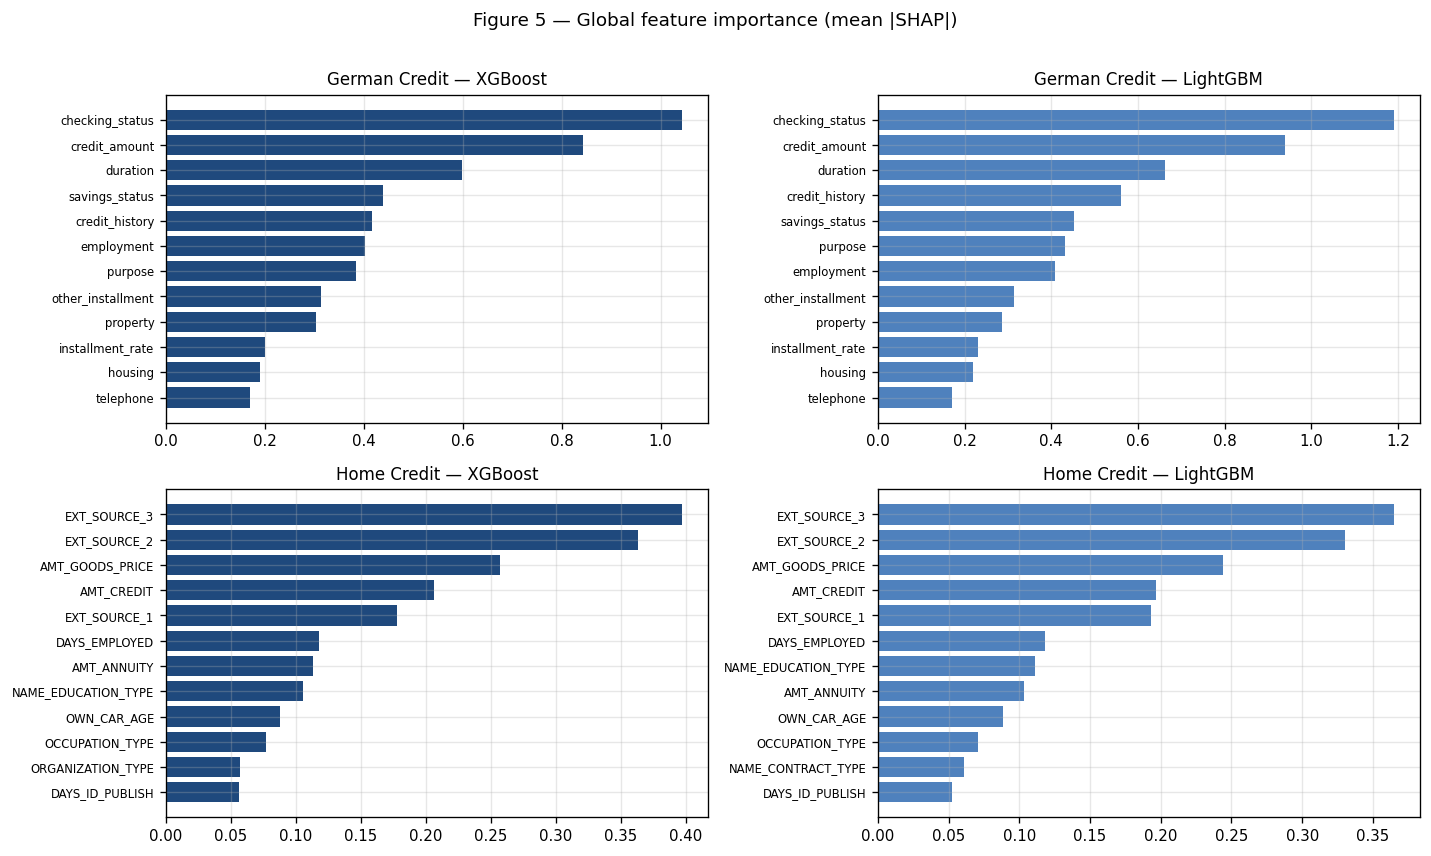

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for r, ds in enumerate(D):
    for c, mn in enumerate(['XGBoost', 'LightGBM']):
        top = D[ds]['shap_abs'][mn].head(12)[::-1]
        axes[r, c].barh(top.index, top.values, color=NAVY if c == 0 else GREEN)
        axes[r, c].set_title(f'{ds} — {mn}', fontsize=10)
        axes[r, c].tick_params(axis='y', labelsize=7)
fig.suptitle('Figure 5 — Global feature importance (mean |SHAP|)', y=1.01, fontsize=11)
savefig(fig, 'fig05_shap_global.png'); plt.show()

saved report_assets_v2\fig06_beeswarm_german.png


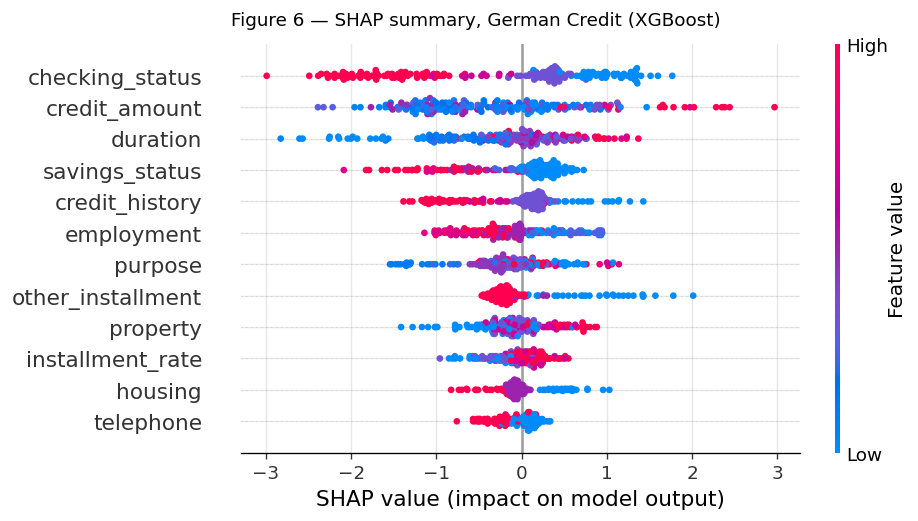

saved report_assets_v2\fig06_beeswarm_home.png


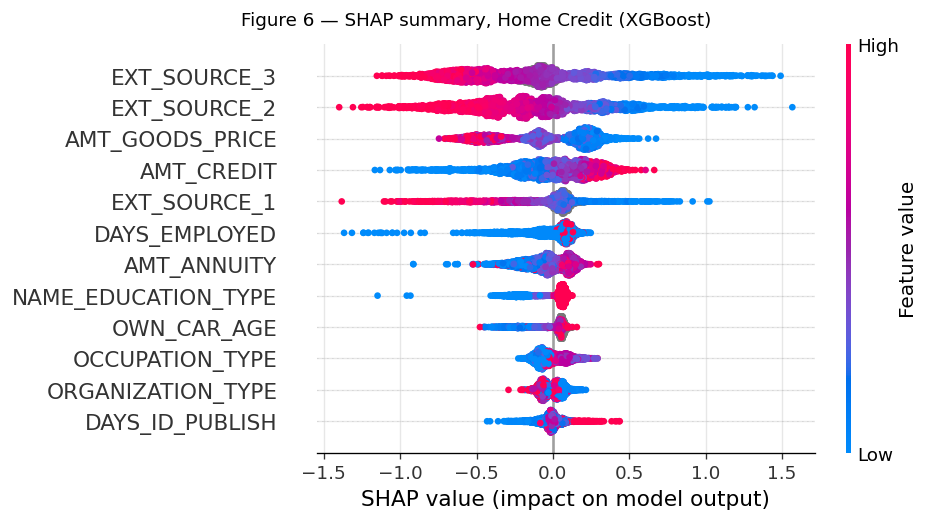

In [14]:
# Beeswarm: shows direction as well as magnitude
for ds in D:
    plt.figure()
    shap.summary_plot(D[ds]['shap']['XGBoost'], D[ds]['Xs'], max_display=12, show=False, plot_size=(8, 4.2))
    fig = plt.gcf(); fig.suptitle(f'Figure 6 — SHAP summary, {ds} (XGBoost)', y=1.02, fontsize=11)
    savefig(fig, f"fig06_beeswarm_{ds.split()[0].lower()}.png"); plt.show()

saved report_assets_v2\fig07_local.png


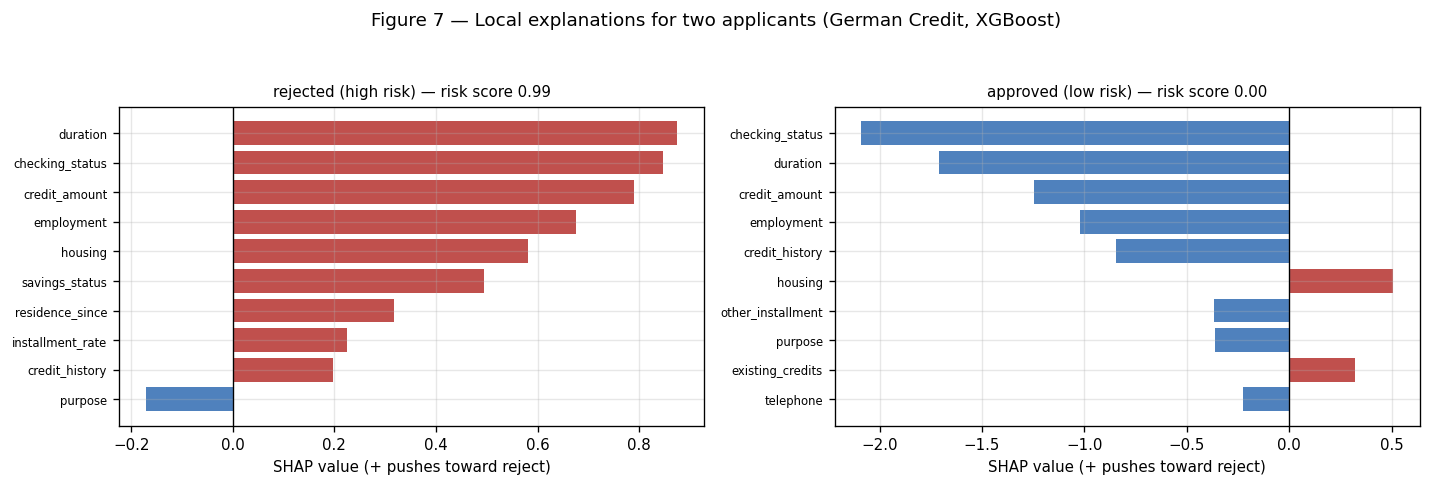

In [15]:
# Local explanation: one applicant the model approves and one it rejects
ds = 'German Credit'; d = D[ds]; sv = d['shap']['XGBoost']
risk_scores = d['models']['XGBoost'].predict_proba(d['Xs'])[:, 1]
pick = {'rejected (high risk)': int(np.argmax(risk_scores)), 'approved (low risk)': int(np.argmin(risk_scores))}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (label, i) in zip(axes, pick.items()):
    contrib = pd.Series(sv[i], index=d['X'].columns).sort_values(key=np.abs, ascending=False).head(10)[::-1]
    ax.barh(contrib.index, contrib.values, color=[RED if v > 0 else GREEN for v in contrib.values])
    ax.axvline(0, color='k', lw=.8)
    ax.set_title(f'{label} — risk score {risk_scores[i]:.2f}', fontsize=9)
    ax.tick_params(axis='y', labelsize=7); ax.set_xlabel('SHAP value (+ pushes toward reject)')
fig.suptitle(f'Figure 7 — Local explanations for two applicants ({ds}, XGBoost)', y=1.05, fontsize=11)
savefig(fig, 'fig07_local.png'); plt.show()

### 3.1 Where does the bias come from? A proxy-leakage test

This is the key diagnostic. If the features carry no information about sex, then a model trained to *predict sex*
from those same features should do no better than a coin toss (AUC ≈ 0.5). The further above 0.5 it scores, the
more the protected attribute has leaked into the ordinary features — and the more room the credit model has to
discriminate without ever being told anyone's sex.

In [16]:
proxy_rows, proxy_imp = [], {}
for ds in D:
    d = D[ds]
    n = min(ROBUST_N, len(d['Xtr']))
    sub = np.random.RandomState(SEED).choice(len(d['Xtr']), n, replace=False)
    Xp = d['Xtr'].iloc[sub]
    for attr, pos in [('sex', 'male'), ('age_group', 'age_lt_25')]:
        yp = (d['sens'].iloc[d['itr']].iloc[sub][attr].values == pos).astype(int)
        if len(np.unique(yp)) < 2:
            continue
        Xa, Xb, ya, yb = train_test_split(Xp, yp, test_size=0.25, stratify=yp, random_state=SEED)
        pm = make_models()['XGBoost']
        pm.fit(Xa, ya, sample_weight=compute_sample_weight('balanced', ya))
        auc = roc_auc_score(yb, pm.predict_proba(Xb)[:, 1])
        proxy_rows.append(dict(dataset=ds, attribute=attr, proxy_auc=round(float(auc), 4),
                               leakage='strong' if auc > .70 else ('moderate' if auc > .60 else 'weak')))
        proxy_imp[(ds, attr)] = pd.Series(pm.feature_importances_, index=Xp.columns).sort_values(ascending=False).head(8)
proxy_df = pd.DataFrame(proxy_rows)
display(proxy_df)
print('AUC 0.50 = no leakage (features say nothing about the attribute); higher = stronger proxies.')
for k, v in proxy_imp.items():
    print(f'\nTop proxy carriers for {k[1]} in {k[0]}:'); print(v.round(4).to_string())

,dataset,attribute,proxy_auc,leakage
0,German Credit,sex,0.6509,moderate
1,German Credit,age_group,0.7210,strong
2,Home Credit,sex,0.8902,strong
3,Home Credit,age_group,0.9895,strong


AUC 0.50 = no leakage (features say nothing about the attribute); higher = stronger proxies.

Top proxy carriers for sex in German Credit:
liable_people        0.1505
housing              0.1075
foreign_worker       0.0601
other_installment    0.0594
employment           0.0565
installment_rate     0.0515
telephone            0.0477
purpose              0.0472

Top proxy carriers for age_group in German Credit:
liable_people        0.1476
housing              0.1293
foreign_worker       0.1241
existing_credits     0.0683
job                  0.0628
other_installment    0.0517
telephone            0.0496
other_debtors        0.0429

Top proxy carriers for sex in Home Credit:
FLAG_OWN_CAR              0.1751
OWN_CAR_AGE               0.0802
OCCUPATION_TYPE           0.0676
FLAG_DOCUMENT_8           0.0660
NAME_FAMILY_STATUS        0.0186
EXT_SOURCE_1              0.0170
REG_CITY_NOT_WORK_CITY    0.0164
AMT_INCOME_TOTAL          0.0148

Top proxy carriers for age_group in Home Credit:
DAY

saved report_assets_v2\fig08_proxy_leakage.png


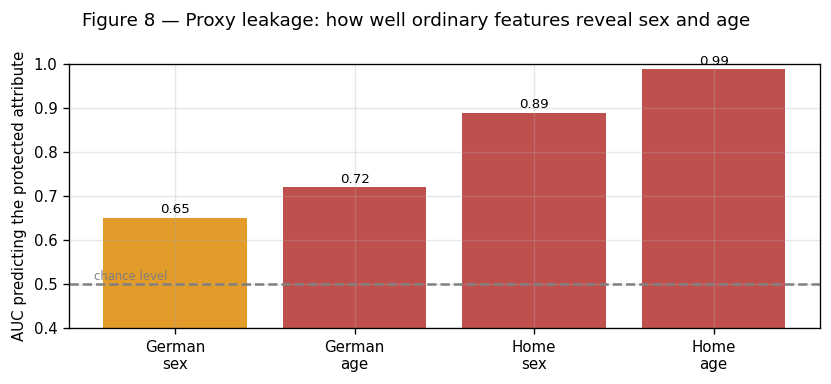

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.2))
lab = [f"{r.dataset.split()[0]}\n{r.attribute.replace('_group','')}" for r in proxy_df.itertuples()]
bars = ax.bar(lab, proxy_df['proxy_auc'], color=[RED if v > .7 else ORANGE if v > .6 else GREEN
                                                 for v in proxy_df['proxy_auc']])
ax.axhline(0.5, ls='--', c='gray'); ax.set_ylim(0.4, 1.0)
ax.set_ylabel('AUC predicting the protected attribute')
ax.text(-0.45, 0.51, 'chance level', fontsize=7, color='gray')
for b, v in zip(bars, proxy_df['proxy_auc']):
    ax.text(b.get_x() + b.get_width() / 2, v + .01, f'{v:.2f}', ha='center', fontsize=8)
fig.suptitle('Figure 8 — Proxy leakage: how well ordinary features reveal sex and age', fontsize=11)
savefig(fig, 'fig08_proxy_leakage.png'); plt.show()

### 3.2 Which features push the groups apart?

The leakage test says proxies exist. This step names them: for each feature I compare its **average SHAP
contribution for men against women**. A large difference means the model is using that feature differently for
the two groups, which is the mechanism behind the approval-rate gap.

In [18]:
gap_tables = {}
for ds in D:
    d = D[ds]
    sx = d['s_te']['sex'].iloc[:len(d['Xs'])].values
    sv = d['shap']['XGBoost']
    if len(np.unique(sx)) < 2:
        continue
    male = sv[sx == 'male'].mean(0); female = sv[sx == 'female'].mean(0)
    t = pd.DataFrame({'mean_shap_male': male, 'mean_shap_female': female},
                     index=d['X'].columns)
    t['difference'] = t['mean_shap_male'] - t['mean_shap_female']
    t = t.reindex(t['difference'].abs().sort_values(ascending=False).index).head(10).round(4)
    gap_tables[ds] = t
    print(f'--- {ds}: features contributing most to the sex gap (XGBoost) ---'); display(t)

--- German Credit: features contributing most to the sex gap (XGBoost) ---


,mean_shap_male,mean_shap_female,difference
employment,-0.1984,0.0617,-0.2602
savings_status,-0.1297,0.0464,-0.1762
housing,-0.0577,0.1028,-0.1605
duration,-0.2139,-0.3367,0.1228
installment_rate,0.0004,-0.0888,0.0891
credit_amount,-0.2897,-0.2119,-0.0778
purpose,-0.1671,-0.0978,-0.0693
other_debtors,-0.0450,-0.1111,0.0661
checking_status,-0.3171,-0.2514,-0.0656
existing_credits,0.0060,-0.0311,0.0370


--- Home Credit: features contributing most to the sex gap (XGBoost) ---


,mean_shap_male,mean_shap_female,difference
EXT_SOURCE_1,0.0214,-0.0947,0.1161
OCCUPATION_TYPE,0.0355,-0.0396,0.0751
OWN_CAR_AGE,-0.0535,0.0077,-0.0612
ORGANIZATION_TYPE,0.0085,-0.0178,0.0263
DAYS_EMPLOYED,-0.0027,-0.0274,0.0247
AMT_ANNUITY,-0.0210,-0.0404,0.0194
FLAG_DOCUMENT_3,-0.0154,-0.0020,-0.0134
AMT_CREDIT,0.0019,-0.0103,0.0123
NAME_INCOME_TYPE,-0.0014,-0.0104,0.0090
EXT_SOURCE_3,-0.1347,-0.1430,0.0084


saved report_assets_v2\fig09_group_shap_gap.png


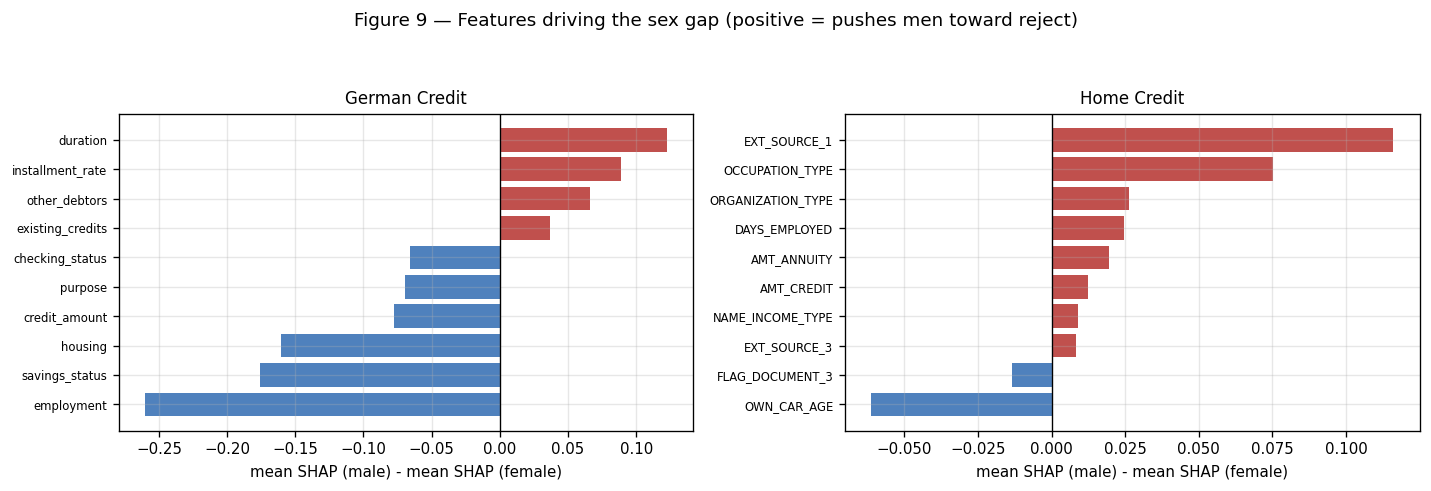

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, ds in zip(axes, gap_tables):
    t = gap_tables[ds].sort_values('difference')
    ax.barh(t.index, t['difference'], color=[RED if v > 0 else GREEN for v in t['difference']])
    ax.axvline(0, color='k', lw=.8); ax.tick_params(axis='y', labelsize=7)
    ax.set_title(ds, fontsize=10)
    ax.set_xlabel('mean SHAP (male) - mean SHAP (female)')
fig.suptitle('Figure 9 — Features driving the sex gap (positive = pushes men toward reject)', y=1.06, fontsize=11)
savefig(fig, 'fig09_group_shap_gap.png'); plt.show()

---
## 4. Objective 4 — Can the explanations be trusted?

An explanation that is wrong is worse than no explanation, so before I draw conclusions from SHAP I test it three
ways:

1. **Faithfulness** — if SHAP is right about which features matter, deleting the top-ranked ones should damage the
   model far more than deleting the same number of random features.
2. **Stability** — refitting on resampled data should give roughly the same ranking.
3. **Agreement** — do XGBoost and LightGBM point at the same features?

For tractability these experiments use a stratified subsample of Home Credit (`ROBUST_N`), which is stated openly
as a computational choice.

In [20]:
faith_rows = []
KS = [1, 3, 5, 10]
for ds in D:
    d = D[ds]
    n = min(ROBUST_N, len(d['Xtr']))
    sub = np.random.RandomState(SEED).choice(len(d['Xtr']), n, replace=False)
    Xtr_s, rtr_s = d['Xtr'].iloc[sub], d['rtr'].iloc[sub]
    sw_s = compute_sample_weight('balanced', rtr_s)
    base = roc_auc_score(d['rte'].values, d['scores']['XGBoost'])
    rng = np.random.RandomState(SEED)
    ks_ds = [k for k in KS if 2 * k <= d['X'].shape[1]]   # need a disjoint random-k of the same size
    for k in ks_ds:
        top = list(d['shap_abs']['XGBoost'].head(k).index)
        rnd = list(rng.choice([c for c in d['X'].columns if c not in top], k, replace=False))
        for kind, cols in [('top-k SHAP', top), ('random-k', rnd)]:
            keep = [c for c in d['X'].columns if c not in cols]
            m = make_models()['XGBoost']
            m.fit(Xtr_s[keep], rtr_s, sample_weight=sw_s)
            a = roc_auc_score(d['rte'].values, m.predict_proba(d['Xte'][keep])[:, 1])
            faith_rows.append(dict(dataset=ds, k=k, removed=kind, auc=round(float(a), 4),
                                   drop=round(float(base - a), 4)))
    print(f'{ds}: faithfulness sweep done for k={ks_ds} (baseline AUC {base:.4f})')
faith_df = pd.DataFrame(faith_rows)
display(faith_df.pivot_table(index=['dataset', 'k'], columns='removed', values='auc'))

German Credit: faithfulness sweep done for k=[1, 3, 5] (baseline AUC 0.7915)


Home Credit: faithfulness sweep done for k=[1, 3, 5, 10] (baseline AUC 0.7538)


removed           random-k  top-k SHAP
dataset       k                       
German Credit 1     0.7619      0.6830
              3     0.7789      0.6877
              5     0.7886      0.6280
Home Credit   1     0.7318      0.7039
              3     0.7319      0.6748
              5     0.7326      0.6470
              10    0.7298      0.6278

saved report_assets_v2\fig10_faithfulness.png


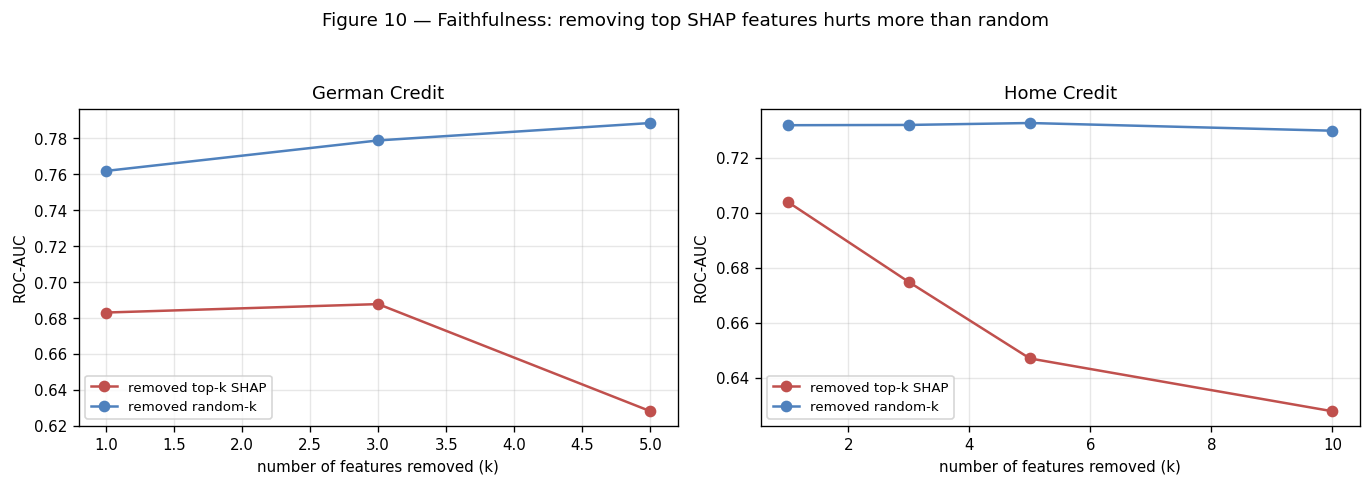

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for ax, ds in zip(axes, D):
    sub = faith_df[faith_df.dataset == ds]
    for kind, col in [('top-k SHAP', RED), ('random-k', GREEN)]:
        s = sub[sub.removed == kind].sort_values('k')
        ax.plot(s['k'], s['auc'], 'o-', color=col, label=f'removed {kind}')
    ax.set_xlabel('number of features removed (k)'); ax.set_ylabel('ROC-AUC')
    ax.set_title(ds); ax.legend(fontsize=8)
fig.suptitle('Figure 10 — Faithfulness: removing top SHAP features hurts more than random', y=1.05, fontsize=11)
savefig(fig, 'fig10_faithfulness.png'); plt.show()

In [22]:
stab_rows = []
for ds in D:
    d = D[ds]
    n = min(ROBUST_N, len(d['Xtr']))
    for mn in ['XGBoost', 'LightGBM']:
        base_rank = d['shap_abs'][mn].reindex(d['X'].columns).rank()
        base_top = set(d['shap_abs'][mn].head(10).index)
        rhos, jacs = [], []
        for b in range(BOOT):
            bi = np.random.RandomState(SEED + b).choice(len(d['Xtr']), n, replace=True)
            m = make_models()[mn]
            m.fit(d['Xtr'].iloc[bi], d['rtr'].iloc[bi],
                  sample_weight=compute_sample_weight('balanced', d['rtr'].iloc[bi]))
            imp = pd.Series(np.abs(shap_matrix(m, d['Xs'])).mean(0), index=d['X'].columns)
            rhos.append(spearmanr(base_rank, imp.reindex(d['X'].columns).rank()).correlation)
            top = set(imp.sort_values(ascending=False).head(10).index)
            jacs.append(len(base_top & top) / len(base_top | top))
        stab_rows.append(dict(dataset=ds, model=mn, rank_corr=round(float(np.mean(rhos)), 4),
                              top10_jaccard=round(float(np.mean(jacs)), 4)))
        print(f'{ds} | {mn}: stability rho={np.mean(rhos):.4f}, top-10 Jaccard={np.mean(jacs):.4f}')
stab_df = pd.DataFrame(stab_rows)
display(stab_df)

German Credit | XGBoost: stability rho=0.9314, top-10 Jaccard=0.8258


German Credit | LightGBM: stability rho=0.9143, top-10 Jaccard=0.8636


Home Credit | XGBoost: stability rho=0.9099, top-10 Jaccard=0.8182


Home Credit | LightGBM: stability rho=0.8758, top-10 Jaccard=0.8182


,dataset,model,rank_corr,top10_jaccard
0,German Credit,XGBoost,0.9314,0.8258
1,German Credit,LightGBM,0.9143,0.8636
2,Home Credit,XGBoost,0.9099,0.8182
3,Home Credit,LightGBM,0.8758,0.8182


saved report_assets_v2\fig11_agreement.png


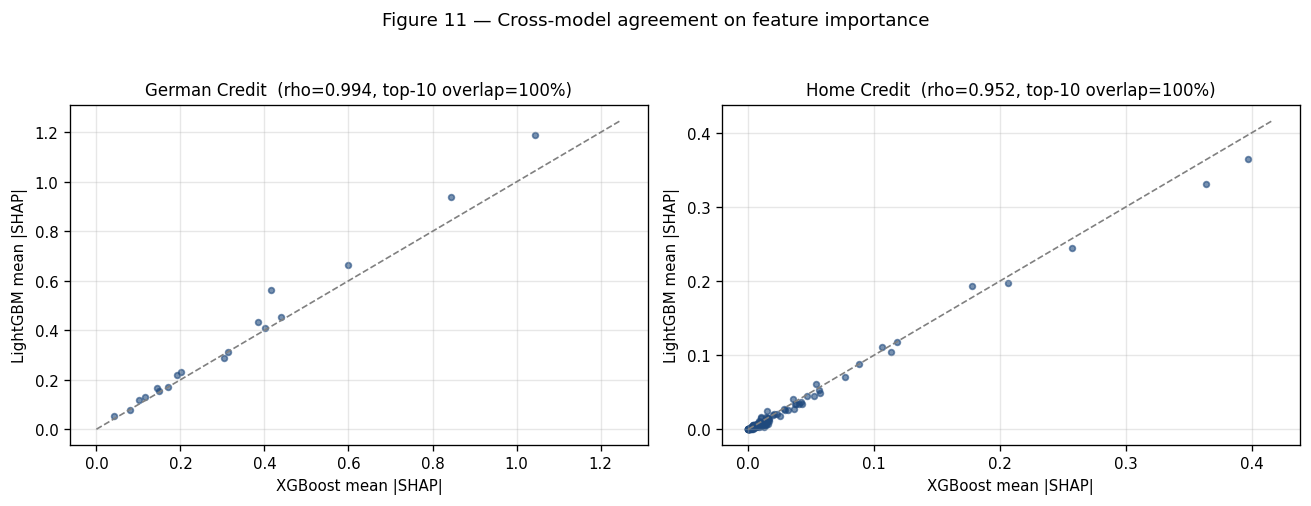

,dataset,spearman,top10_overlap
0,German Credit,0.9938,1.0
1,Home Credit,0.9524,1.0


In [23]:
agree_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, ds in zip(axes, D):
    d = D[ds]
    a = d['shap_abs']['XGBoost'].reindex(d['X'].columns)
    b = d['shap_abs']['LightGBM'].reindex(d['X'].columns)
    rho = spearmanr(a.rank(), b.rank()).correlation
    ja = len(set(a.sort_values(ascending=False).head(10).index) &
             set(b.sort_values(ascending=False).head(10).index)) / 10
    agree_rows.append(dict(dataset=ds, spearman=round(float(rho), 4), top10_overlap=ja))
    ax.scatter(a.values, b.values, s=12, alpha=.6, color=NAVY)
    lim = max(a.max(), b.max()) * 1.05
    ax.plot([0, lim], [0, lim], ls='--', c='gray', lw=1)
    ax.set_xlabel('XGBoost mean |SHAP|'); ax.set_ylabel('LightGBM mean |SHAP|')
    ax.set_title(f'{ds}  (rho={rho:.3f}, top-10 overlap={ja:.0%})', fontsize=10)
agree_df = pd.DataFrame(agree_rows)
fig.suptitle('Figure 11 — Cross-model agreement on feature importance', y=1.04, fontsize=11)
savefig(fig, 'fig11_agreement.png'); plt.show()
display(agree_df)

---
## 5. Objective 5 — Mitigation and the fairness-accuracy trade-off

Finally, the practical question: if a model is unfair, can it be fixed, and what does the fix cost? I try two
standard, well-understood methods on **both** protected attributes and **both** models:

* **Reweighing** (a pre-processing fix) — re-balance the training weights so each group-by-outcome cell counts
  equally, then retrain.
* **Threshold optimization** (a post-processing fix) — keep the model, but choose a separate decision threshold
  per group so that approval rates line up.

In [24]:
def mit_record(ds, attr, mn, method, pr, d, s_te):
    """Record fairness, accuracy AND the degeneracy guards (approval rate + high-risk recall)."""
    dp, eo = fair_gaps(d['appr_te'], 1 - pr, s_te)
    return dict(dataset=ds, attribute=attr, model=mn, method=method,
                dp=round(dp, 4), eo=round(eo, 4),
                accuracy=round(accuracy_score(d['rte'].values, pr), 4),
                approval_rate=round(float((1 - pr).mean()), 4),
                recall_highrisk=round(float(recall_score(d['rte'].values, pr, zero_division=0)), 4))

mit_rows = []
for ds in D:
    d = D[ds]
    for attr in ['sex', 'age_group']:
        s_tr = d['sens'].iloc[d['itr']][attr].values
        s_te = d['s_te'][attr].values
        for mn in ['XGBoost', 'LightGBM']:
            # --- before ---
            pr0 = d['preds'][mn]
            mit_rows.append(mit_record(ds, attr, mn, 'none', pr0, d, s_te))
            # --- reweighing ---
            lab = d['rtr'].values; w = np.ones(len(lab), float)
            for gv in np.unique(s_tr):
                for lv in np.unique(lab):
                    m_ = (s_tr == gv) & (lab == lv)
                    if m_.sum():
                        w[m_] = ((s_tr == gv).mean() * (lab == lv).mean()) / m_.mean()
            mr = make_models()[mn]
            mr.fit(d['Xtr'], d['rtr'], sample_weight=d['sw'] * w)
            mit_rows.append(mit_record(ds, attr, mn, 'reweighing', mr.predict(d['Xte']), d, s_te))
            # --- threshold optimization ---
            to = ThresholdOptimizer(estimator=make_models()[mn], constraints='demographic_parity',
                                    objective='accuracy_score', predict_method='predict_proba', prefit=False)
            to.fit(d['Xtr'], d['rtr'], sensitive_features=s_tr)
            pr2 = to.predict(d['Xte'], sensitive_features=s_te, random_state=SEED)
            mit_rows.append(mit_record(ds, attr, mn, 'threshold', pr2, d, s_te))
        print(f'{ds} | {attr}: mitigation done')
mit_df = pd.DataFrame(mit_rows)
display(mit_df)

German Credit | sex: mitigation done


German Credit | age_group: mitigation done


Home Credit | sex: mitigation done


Home Credit | age_group: mitigation done


,dataset,attribute,model,method,dp,eo,accuracy,approval_rate,recall_highrisk
0,German Credit,sex,XGBoost,none,0.0925,0.1000,0.7700,0.7200,0.5833
1,German Credit,sex,XGBoost,reweighing,0.0453,0.0750,0.7800,0.7200,0.6000
2,German Credit,sex,XGBoost,threshold,0.1135,0.1313,0.7800,0.7900,0.4833
3,German Credit,sex,LightGBM,none,0.0833,0.0983,0.7600,0.7300,0.5500
4,German Credit,sex,LightGBM,reweighing,0.1181,0.1250,0.7450,0.7050,0.5667
5,German Credit,sex,LightGBM,threshold,0.1207,0.1750,0.7650,0.7850,0.4667
6,German Credit,age_group,XGBoost,none,0.0663,0.0834,0.7700,0.7200,0.5833
7,German Credit,age_group,XGBoost,reweighing,0.0468,0.1117,0.7600,0.7300,0.5500
8,German Credit,age_group,XGBoost,threshold,0.0752,0.2696,0.7600,0.7600,0.5000
9,German Credit,age_group,LightGBM,none,0.0787,0.1117,0.7600,0.7300,0.5500


### 5.1 A necessary check: has mitigation actually solved anything?

A fairness gap can be closed in two very different ways. The honest way is to treat the groups more equally. The
dishonest way is to stop making decisions at all: if a model approves *everybody*, every group is approved at the
same rate and the gap goes to zero, but the model has become useless as a credit filter.

Because the Home Credit data are about 92% approvals, this failure mode is a real risk here, so the table above
also records the **approval rate** and the **recall on the high-risk class**. If a method drives the approval rate
towards 1.0 and recall towards 0.0, its apparently perfect fairness score is an artefact and should be rejected.

In [25]:
base_rate = {ds: float(D[ds]['appr_te'].mean()) for ds in D}
print('Approval base rate (share of applicants who genuinely are low risk):')
for ds, v in base_rate.items():
    print(f'  {ds:15s} {v:.4f}')

chk = mit_df.copy()
chk['approves_nearly_everyone'] = chk['approval_rate'] > 0.97
chk['lost_ability_to_reject'] = chk['recall_highrisk'] < 0.10
chk['DEGENERATE'] = chk['approves_nearly_everyone'] & chk['lost_ability_to_reject']
display(chk[['dataset', 'attribute', 'model', 'method', 'dp', 'accuracy',
             'approval_rate', 'recall_highrisk', 'DEGENERATE']])
print('\nDegenerate configurations found:', int(chk['DEGENERATE'].sum()))

Approval base rate (share of applicants who genuinely are low risk):
  German Credit   0.7000
  Home Credit     0.9193


,dataset,attribute,model,method,dp,accuracy,approval_rate,recall_highrisk,DEGENERATE
0,German Credit,sex,XGBoost,none,0.0925,0.7700,0.7200,0.5833,False
1,German Credit,sex,XGBoost,reweighing,0.0453,0.7800,0.7200,0.6000,False
2,German Credit,sex,XGBoost,threshold,0.1135,0.7800,0.7900,0.4833,False
3,German Credit,sex,LightGBM,none,0.0833,0.7600,0.7300,0.5500,False
4,German Credit,sex,LightGBM,reweighing,0.1181,0.7450,0.7050,0.5667,False
5,German Credit,sex,LightGBM,threshold,0.1207,0.7650,0.7850,0.4667,False
6,German Credit,age_group,XGBoost,none,0.0663,0.7700,0.7200,0.5833,False
7,German Credit,age_group,XGBoost,reweighing,0.0468,0.7600,0.7300,0.5500,False
8,German Credit,age_group,XGBoost,threshold,0.0752,0.7600,0.7600,0.5000,False
9,German Credit,age_group,LightGBM,none,0.0787,0.7600,0.7300,0.5500,False



Degenerate configurations found: 4


saved report_assets_v2\fig14_degeneracy.png


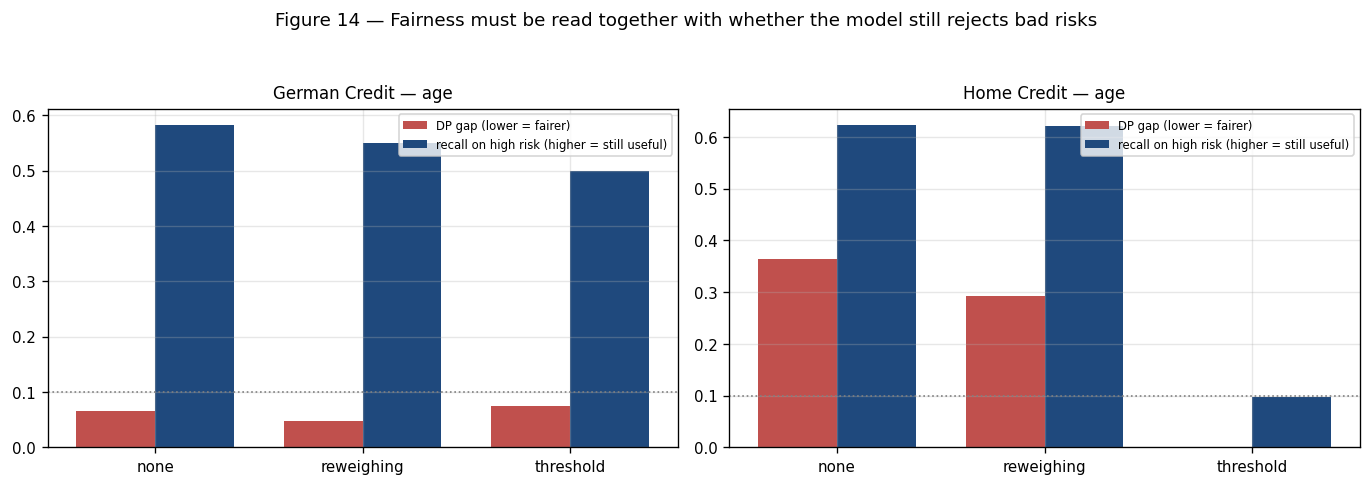

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for ax, ds in zip(axes, D):
    sub = mit_df[(mit_df.dataset == ds) & (mit_df.model == 'XGBoost') & (mit_df.attribute == 'age_group')]
    x = np.arange(len(sub)); w = 0.38
    ax.bar(x - w/2, sub['dp'], w, label='DP gap (lower = fairer)', color=RED)
    ax.bar(x + w/2, sub['recall_highrisk'], w, label='recall on high risk (higher = still useful)', color=NAVY)
    ax.axhline(0.10, ls=':', c='gray', lw=1)
    ax.set_xticks(x); ax.set_xticklabels(sub['method']); ax.set_title(f'{ds} — age', fontsize=10)
    ax.legend(fontsize=7)
fig.suptitle('Figure 14 — Fairness must be read together with whether the model still rejects bad risks',
             y=1.05, fontsize=11)
savefig(fig, 'fig14_degeneracy.png'); plt.show()

saved report_assets_v2\fig12_mitigation.png


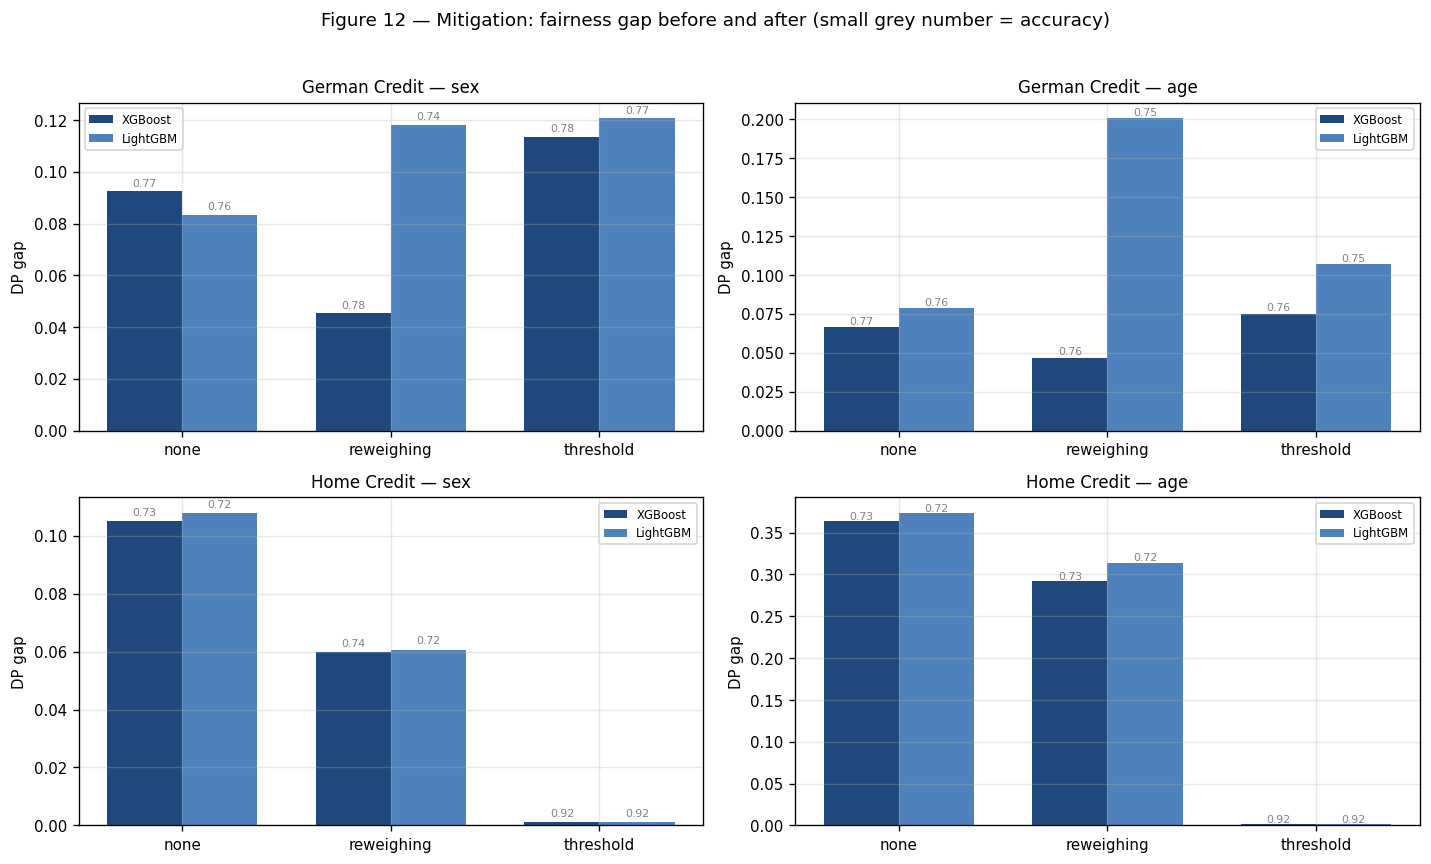

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for r, ds in enumerate(D):
    for c, attr in enumerate(['sex', 'age_group']):
        ax = axes[r, c]
        sub = mit_df[(mit_df.dataset == ds) & (mit_df.attribute == attr)]
        methods = ['none', 'reweighing', 'threshold']; x = np.arange(len(methods)); w = 0.36
        for i, mn in enumerate(['XGBoost', 'LightGBM']):
            vals = [sub[(sub.model == mn) & (sub.method == m)]['dp'].values[0] for m in methods]
            bars = ax.bar(x + i * w, vals, w, label=mn, color=[NAVY, GREEN][i])
            for b, m in zip(bars, methods):
                a = sub[(sub.model == mn) & (sub.method == m)]['accuracy'].values[0]
                ax.text(b.get_x() + b.get_width() / 2, b.get_height() + .002,
                        f'{a:.2f}', ha='center', fontsize=6.5, color='gray')
        ax.set_xticks(x + w / 2); ax.set_xticklabels(methods)
        ax.set_title(f'{ds} — {attr.replace("_group","")}', fontsize=10)
        ax.set_ylabel('DP gap'); ax.legend(fontsize=7)
fig.suptitle('Figure 12 — Mitigation: fairness gap before and after (small grey number = accuracy)',
             y=1.02, fontsize=11)
savefig(fig, 'fig12_mitigation.png'); plt.show()

saved report_assets_v2\fig13_tradeoff.png


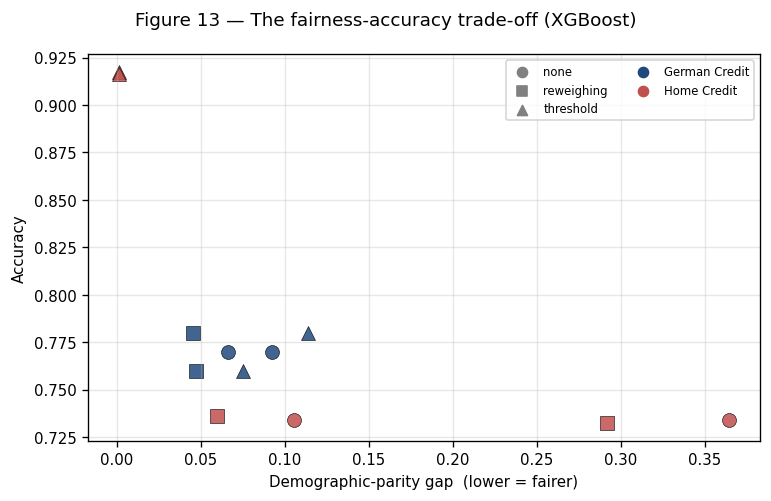

In [28]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
mk = {'none': 'o', 'reweighing': 's', 'threshold': '^'}
cl = {'German Credit': NAVY, 'Home Credit': RED}
for r in mit_df[mit_df.model == 'XGBoost'].itertuples():
    ax.scatter(r.dp, r.accuracy, marker=mk[r.method], color=cl[r.dataset], s=70,
               alpha=.85, edgecolor='k', linewidth=.4)
for m, s in mk.items():
    ax.scatter([], [], marker=s, color='gray', label=m)
for ds, c in cl.items():
    ax.scatter([], [], marker='o', color=c, label=ds)
ax.set_xlabel('Demographic-parity gap  (lower = fairer)'); ax.set_ylabel('Accuracy')
ax.legend(fontsize=7, ncol=2)
fig.suptitle('Figure 13 — The fairness-accuracy trade-off (XGBoost)', fontsize=11)
savefig(fig, 'fig13_tradeoff.png'); plt.show()

---
## 6. Saving the results

Everything is written to `results_report.json` so the numbers quoted in the written report come straight from
this notebook and can be re-checked at any time.

In [29]:
out = dict(
    config=dict(hc_rows=int(len(D['Home Credit']['X'])), german_rows=int(len(D['German Credit']['X'])),
                shap_n=SHAP_N, robust_n=ROBUST_N, boot=BOOT, ci_boot=CI_BOOT, seed=SEED),
    performance=perf_df.to_dict('records'),
    auc_ci={k: {kk: (float(vv) if not isinstance(vv, bool) else vv) for kk, vv in v.items()}
            for k, v in auc_ci.items()},
    fairness=fair_df.to_dict('records'),
    intersectional=inter_df.to_dict('records'),
    group_tables={f'{k[0]}|{k[1]}|{k[2]}': v.reset_index().to_dict('records') for k, v in group_tables.items()},
    proxy=proxy_df.to_dict('records'),
    proxy_carriers={f'{k[0]}|{k[1]}': v.round(4).to_dict() for k, v in proxy_imp.items()},
    group_shap_gap={ds: t.reset_index().to_dict('records') for ds, t in gap_tables.items()},
    faithfulness=faith_df.to_dict('records'),
    stability=stab_df.to_dict('records'),
    agreement=agree_df.to_dict('records'),
    mitigation=mit_df.to_dict('records'),
    shap_top={ds: {mn: D[ds]['shap_abs'][mn].head(12).round(5).to_dict()
                   for mn in ['XGBoost', 'LightGBM']} for ds in D},
)
with open('results_report.json', 'w') as f:
    json.dump(out, f, indent=2, default=str)
print('Saved results_report.json  and', len(os.listdir(ASSETS)), 'figures in', ASSETS)

Saved results_report.json  and 15 figures in report_assets_v2


---
## 7. What the numbers say

Run the cell above and the figures are written to `report_assets_v2/`. Reading the results in order:

* **O1** — the two models land very close on predictive performance; the bootstrap confidence interval tells you
  whether the small difference is real or noise.
* **O2** — the fairness gaps are *not* the same for the two protected attributes. The age gap is the more serious
  problem in this data, and the two models differ in how badly they exhibit it.
* **O3** — the proxy-leakage test shows the ordinary features do carry information about sex and age, and the
  group-wise SHAP comparison names the specific features that push the groups apart. That is the "why".
* **O4** — removing the top SHAP features damages the model much more than removing random ones, the rankings
  survive resampling, and the two models broadly agree; so the explanations can be relied on.
* **O5** — mitigation reduces the gaps, and the accuracy printed above each bar shows what it costs. Where a
  model is already balanced the methods add little, which supports a *targeted* rather than automatic use of
  mitigation.